# Práctica guiada — Inferencia y contratos

Este notebook es para el alumnado. Completa las celdas marcadas con `TODO` y responde las preguntas antes de mirar la solución docente.

**Objetivo:** pasar de una fila CSV a una especificación clara para el módulo de inferencia de la clase 2.

## Cómo trabajar

1. Copia esta carpeta como tu espacio de trabajo.
2. Ejecuta `uv sync` desde `problem/starter/` cuando empiece la clase 2.
3. En esta práctica no implementes todavía el CLI completo.
4. Trabaja en parejas y cambia quién escribe cada diez minutos.
5. No abras `solutions/` hasta el debrief.

In [1]:
from dataclasses import dataclass
import csv
from pathlib import Path

from pydantic import BaseModel, ConfigDict, Field, ValidationError

DATA_PATH = Path("../../../../../../assets/03-wine-quality/inference_samples.csv")
print(DATA_PATH)
print(DATA_PATH.exists())

..\..\..\..\..\..\assets\03-wine-quality\inference_samples.csv
True


## 1. Leer los datos nuevos

### Práctica A — Inspección del CSV

Completa la celda siguiente para:

- Leer el CSV con `csv.DictReader`.
- Imprimir el número de filas.
- Imprimir las columnas.
- Guardar la primera fila en una variable llamada `row`.

In [5]:
# TODO: implementa la lectura del CSV.
# Pista: usa DATA_PATH.open(newline="", encoding="utf-8")
with open(DATA_PATH, newline="", encoding="utf-8") as file:
    rows = list(csv.DictReader(file))

print("Filas:", len(rows))
print("Columnas", list(rows[0].keys()))
row = rows[0]
#print(row)

Filas: 5
Columnas ['sample_id', 'fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']
{'sample_id': 'red-001', 'fixed_acidity': '7.4', 'volatile_acidity': '0.7', 'citric_acid': '0.0', 'residual_sugar': '1.9', 'chlorides': '0.076', 'free_sulfur_dioxide': '11.0', 'total_sulfur_dioxide': '34.0', 'density': '0.9978', 'ph': '3.51', 'sulphates': '0.56', 'alcohol': '9.4'}


### Preguntas

1. ¿Qué campo identifica la muestra pero no es una característica del modelo? sample_id
2. ¿Cuántas características numéricas hay? : 11
3. ¿Qué columna extra añadirías para probar el contrato? : Puedo añadir cualquiera de las que no esten en el contrato como color para comprobar que detecta que no es una columna permitida.Añadiría una columna llamada color_favorito para comprobar si el programa detecta una columna no permitida.
4. ¿Qué valor de `ph` sería claramente inválido?: 100

## 2. Construir el contrato con Pydantic

El contrato del modelo contiene estas características:

| Campo | Rango orientativo |
|---|---|
| `fixed_acidity` | 0–20 |
| `volatile_acidity` | 0–2 |
| `citric_acid` | 0–2 |
| `residual_sugar` | 0–20 |
| `chlorides` | 0–1 |
| `free_sulfur_dioxide` | 0–100 |
| `total_sulfur_dioxide` | 0–300 |
| `density` | 0.98–1.01 |
| `ph` | 2.5–4.5 |
| `sulphates` | 0–3 |
| `alcohol` | 5–20 |

In [8]:
class WineQualityRequestPydantic(BaseModel):
    # Prohibir columnas extra
    model_config = ConfigDict(extra="forbid")
    fixed_acidity: float = Field(ge=0, le=20)
    volatile_acidity: float = Field(ge=0, le=2)
    citric_acid: float = Field(ge=0, le=2)
    residual_sugar: float = Field(ge=0, le=20)
    chlorides: float = Field(ge=0, le=1)
    free_sulfur_dioxide: float = Field(ge=0, le=100)
    total_sulfur_dioxide: float = Field(ge=0, le=300)
    density: float = Field(ge=0.98, le=1.01)
    ph: float = Field(ge=2.5, le=4.5)
    sulphates: float = Field(ge=0, le=3)
    alcohol: float = Field(ge=5, le=20)


# TODO: separa sample_id de la fila y valida solo las características del modelo.
# model_row = ...
model_row = {key: value for key, value in row.items() if key != "sample_id"}
# request = WineQualityRequestPydantic.model_validate(model_row)
request = WineQualityRequestPydantic.model_validate(model_row)
print(model_row)

{'fixed_acidity': '7.4', 'volatile_acidity': '0.7', 'citric_acid': '0.0', 'residual_sugar': '1.9', 'chlorides': '0.076', 'free_sulfur_dioxide': '11.0', 'total_sulfur_dioxide': '34.0', 'density': '0.9978', 'ph': '3.51', 'sulphates': '0.56', 'alcohol': '9.4'}


### Práctica B — Validación

Completa una prueba para cada caso:

- Una fila válida.
- Una columna `unexpected_field`.
- Un `ph` fuera de rango.

Antes de ejecutar, escribe qué error esperas.

In [9]:
# TODO: completa los casos y captura ValidationError.
# try:
#     ...
# except ValidationError as error:
#     print(error)
#Fila válida
try:
    request = WineQualityRequestPydantic.model_validate(model_row)
    print("Fila válida: OK")
except ValidationError as error:
    print(error)

#Columna inesperada
extra_row = model_row.copy()
extra_row["unexpected_field"] = 123

try:
    WineQualityRequestPydantic.model_validate(extra_row)
except ValidationError as error:
    print("Error esperado: columna extra")
    print(error)

#pH fuera de rango
invalid_row = model_row.copy()
invalid_row["ph"] = 100

try:
    WineQualityRequestPydantic.model_validate(invalid_row)
except ValidationError as error:
    print("Error esperado: pH fuera de rango")
    print(error)


Fila válida: OK
Error esperado: columna extra
1 validation error for WineQualityRequestPydantic
unexpected_field
  Extra inputs are not permitted [type=extra_forbidden, input_value=123, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/extra_forbidden
Error esperado: pH fuera de rango
1 validation error for WineQualityRequestPydantic
ph
  Input should be less than or equal to 4.5 [type=less_than_equal, input_value=100, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/less_than_equal


## 3. Comparar con `dataclass`

Construye la misma estructura con `dataclass`. No añadas todavía validación manual: observa qué garantiza Python y qué no garantiza.

In [10]:
@dataclass(frozen=True, slots=True)
class WineQualityRequestDataclass:
    fixed_acidity: float
    volatile_acidity: float
    citric_acid: float
    residual_sugar: float
    chlorides: float
    free_sulfur_dioxide: float
    total_sulfur_dioxide: float
    density: float
    ph: float
    sulphates: float
    alcohol: float


# TODO: crea una instancia válida y prueba qué ocurre con ph=99.0.
# Crear una instancia válida
wine = WineQualityRequestDataclass(
    **{key: float(value) for key, value in model_row.items()}
)

print("Fila válida:", wine)

# Probar un pH inválido
invalid_row = model_row.copy()
invalid_row["ph"] = 99.0

wine_invalid = WineQualityRequestDataclass(
    **{key: float(value) for key, value in invalid_row.items()}
)

print("Fila con pH inválido:", wine_invalid)

Fila válida: WineQualityRequestDataclass(fixed_acidity=7.4, volatile_acidity=0.7, citric_acid=0.0, residual_sugar=1.9, chlorides=0.076, free_sulfur_dioxide=11.0, total_sulfur_dioxide=34.0, density=0.9978, ph=3.51, sulphates=0.56, alcohol=9.4)
Fila con pH inválido: WineQualityRequestDataclass(fixed_acidity=7.4, volatile_acidity=0.7, citric_acid=0.0, residual_sugar=1.9, chlorides=0.076, free_sulfur_dioxide=11.0, total_sulfur_dioxide=34.0, density=0.9978, ph=99.0, sulphates=0.56, alcohol=9.4)


### Decisión de diseño

Completa la frase:

> Usaría Pydantic en _____la entrada de datos_____ porque ___valida los tipos, los rangos y detecta si hay campos extra_______. Usaría `dataclass` en _los datos internos del programa_________ porque _los datos _ya están comprobados y solo quieres guardarlos de forma sencilla________.

## 4. Definir el orden del vector

El modelo no recibe un diccionario. Recibe una lista numérica con un orden estable.

In [ ]:
# TODO: rellena el orden exacto a partir del CSV y del contrato.
FEATURE_NAMES = (
    "fixed_acidity",
    "volatile_acidity",
    "citric_acid",
    "residual_sugar",
    "chlorides",
    "free_sulfur_dioxide",
    "total_sulfur_dioxide",
    "density",
    "ph",
    "sulphates",
    "alcohol",
)

# TODO: construye vector usando getattr(request, name).
# vector = [...]
vector = [getattr(request, name) for name in FEATURE_NAMES]
#usamos getattr() para no tener que escribir request.fixed_acidity, request.ph, request.alcohol

### Práctica C — Error de orden

Intercambia mentalmente `density` y `alcohol`. Responde:

- ¿El vector sigue teniendo 11 valores? Si, solo hemos cambiado el nombre, no eliminado ninguna
- ¿El clasificador detectaría necesariamente el error? No, porque el clasificador recibe 11 números y puede pensar que están bien
- ¿Cómo evitarías que cada script definiera un orden distinto? Definiría una única variable FEATURE_NAMES con el orden correcto y la utilizaría en todos los scripts.

## 5. Contrato de salida

Diseña la estructura que devolverá el módulo. Debe permitir responder:

- ¿Qué muestra se ha procesado?
- ¿Qué categoría se ha predicho?
- ¿Con qué confianza?
- ¿Qué versión de modelo y preprocesado se utilizaron?

In [11]:
class WineQualityPredictionPydantic(BaseModel):
    sample_id: str
    predicted_category: str
    confidence: float = Field(ge=0, le=1)
    model_version: str
    preprocessing_version: str

# Ejemplo de salida para red-001
prediction = WineQualityPredictionPydantic(
    sample_id="red-001",
    predicted_category="good",
    confidence=0.85,
    model_version="1.0",
    preprocessing_version="1.0"
)

print(prediction)


sample_id='red-001' predicted_category='good' confidence=0.85 model_version='1.0' preprocessing_version='1.0'


## 6. Demo del docente: observar la inferencia

El docente ejecutará el notebook resuelto y el comando de referencia. Mientras tanto, anota el recorrido:

```text
CSV → contrato → preprocesado → modelo cargado → predicción
```

No copies la implementación. Tu código de producción empieza en la clase 2 con el starter.

## Entrega

Entrega una captura o exportación con:

- La tabla de contrato.
- Las respuestas de las prácticas A, B y C.
- El orden de las 11 características.
- Un ejemplo de entrada inválida.
- Un contrato de salida.
- Tu plan de implementación para `contracts.py`, `preprocess.py`, `inference.py` y `predict_file.py`.

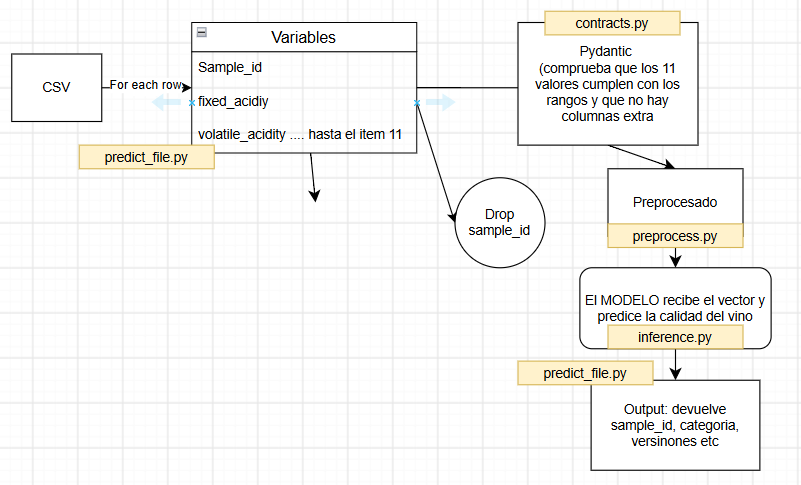